# Predicting High-Engagement Patterns in Short-Form Videos

This notebook implements the final project pipeline for the approved proposal:

- **Task:** Binary classification of **high-engagement** vs **normal-engagement** short-form videos  
- **Dataset:** *YouTube Shorts & TikTok Trends 2025*  
- **Baseline:** Logistic Regression  
- **Deep Learning Model:** Existing MLP implementation using `sklearn.neural_network.MLPClassifier`  
- **Outputs:** validation metrics, test metrics, saved models, confusion matrices, and summary files

> Recommended main setting for the paper: `feature_mode = "strict"` to reduce target leakage.


In [1]:
!pip install -r requirements.txt


   ---------------------------------------- 4/4 [isoduration]




[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
from pathlib import Path
import json
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

DEFAULT_PERCENTILE = 0.75
RANDOM_STATE = 42

## 1. Set paths and experiment options

Update `CSV_PATH` to point to your downloaded Kaggle CSV file.


In [20]:
# ==== USER SETTINGS ====
CSV_PATH = "archive/youtube_shorts_tiktok_trends_2025.csv"   # change this to your local CSV path
OUTPUT_DIR = "outputs_notebook"

TARGET_PERCENTILE = 0.75      # top 25% as high engagement
FEATURE_MODE = "strict"       # "strict" or "full"
HIDDEN_LAYERS = (128, 64)

out_dir = Path(OUTPUT_DIR)
out_dir.mkdir(parents=True, exist_ok=True)

print("CSV_PATH =", CSV_PATH)
print("OUTPUT_DIR =", out_dir.resolve())
print("TARGET_PERCENTILE =", TARGET_PERCENTILE)
print("FEATURE_MODE =", FEATURE_MODE)
print("HIDDEN_LAYERS =", HIDDEN_LAYERS)

CSV_PATH = archive/youtube_shorts_tiktok_trends_2025.csv
OUTPUT_DIR = C:\Users\Allysa\Downloads\CSC753M\outputs_notebook
TARGET_PERCENTILE = 0.75
FEATURE_MODE = strict
HIDDEN_LAYERS = (128, 64)


## 2. Helper functions

In [21]:
# clean column names to snake_case
def snake_case(col: str) -> str:
    col = str(col).strip().lower()
    col = re.sub(r"[^a-z0-9]+", "_", col)
    return re.sub(r"_+", "_", col).strip("_")

# applies snake_case to all columns
def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [snake_case(c) for c in df.columns]
    return df

# create derived text features from title, keywords, tags, comments, etc.
def add_text_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Use the real dataset columns:
    - title
    - title_keywords
    - tags
    - sample_comments

    If title_length / has_emoji already exist, keep them.
    Otherwise derive them.
    """
    df = df.copy()

    # --- title-based features ---
    if "title" in df.columns:
        title_series = df["title"].fillna("").astype(str)

        if "title_length" not in df.columns:
            df["title_length"] = title_series.str.len()

        df["title_word_count"] = title_series.str.split().str.len()

        if "has_emoji" not in df.columns:
            df["has_emoji"] = title_series.apply(
                lambda s: int(any(ord(ch) > 10000 for ch in s))
            )

        df["title_special_char_count"] = title_series.apply(
            lambda s: sum(
                1 for ch in s
                if not ch.isalnum() and not ch.isspace()
            )
        )

    # --- keyword / tag density ---
    if "title_keywords" in df.columns:
        kw = df["title_keywords"].fillna("").astype(str)
        df["title_keywords_length"] = kw.str.len()
        df["title_keywords_word_count"] = kw.str.split().str.len()

    if "tags" in df.columns:
        tags = df["tags"].fillna("").astype(str)
        df["tag_count"] = tags.apply(
            lambda s: 0 if s.strip() == "" else len([x for x in s.split(",") if x.strip()])
        )

    if "sample_comments" in df.columns:
        sc = df["sample_comments"].fillna("").astype(str)
        df["sample_comments_length"] = sc.str.len()

    return df

# force true numeric columns to numeric
def coerce_numeric(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    numeric_candidates = [
        "week_of_year",
        "duration_sec",
        "views",
        "likes",
        "comments",
        "shares",
        "saves",
        "engagement_rate",
        "upload_hour",
        "trend_duration_days",
        "engagement_velocity",
        "dislikes",
        "comment_ratio",
        "share_rate",
        "save_rate",
        "like_dislike_ratio",
        "creator_avg_views",
        "title_length",
        "has_emoji",
        "avg_watch_time_sec",
        "completion_rate",
        "is_weekend",
        "engagement_total",
        "like_rate",
        "dislike_rate",
        "engagement_per_1k",
        "engagement_like_rate",
        "engagement_comment_rate",
        "engagement_share_rate",
        # engineered columns
        "title_word_count",
        "title_special_char_count",
        "title_keywords_length",
        "title_keywords_word_count",
        "tag_count",
        "sample_comments_length",
    ]

    for col in numeric_candidates:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

# build / repair engagement target fields
def build_engagement_target(df: pd.DataFrame) -> pd.DataFrame:
    """
    The uploaded dataset already includes:
    - engagement_rate
    - engagement_total

    But we repair/recompute them safely in case of inconsistencies.
    """
    df = df.copy()

    views = pd.to_numeric(df.get("views", 0), errors="coerce").fillna(0)
    likes = pd.to_numeric(df.get("likes", 0), errors="coerce").fillna(0)
    comments = pd.to_numeric(df.get("comments", 0), errors="coerce").fillna(0)
    shares = pd.to_numeric(df.get("shares", 0), errors="coerce").fillna(0)

    safe_views = views.replace(0, np.nan)

    df["engagement_total"] = likes + comments + shares
    df["engagement_rate"] = (
        df["engagement_total"] / safe_views
    ).replace([np.inf, -np.inf], np.nan).fillna(0)

    return df


# ---------------------------------
# 5. choose feature columns
# ---------------------------------
def choose_feature_columns(df: pd.DataFrame, mode: str = "strict"):
    """
    strict:
        exclude columns directly tied to the target construction
        (views, likes, comments, shares, engagement_rate, etc.)

    full:
        allow leak-prone engagement features too
        mainly for ablation, not for the main paper result
    """
    # safer metadata / context / non-target columns
    strict_numeric_candidates = [
        "week_of_year",
        "duration_sec",
        "upload_hour",
        "trend_duration_days",
        "engagement_velocity",   # arguable, but keep as platform-level dynamic signal
        "creator_avg_views",
        "title_length",
        "title_word_count",
        "title_special_char_count",
        "has_emoji",
        "avg_watch_time_sec",
        "completion_rate",
        "is_weekend",
        "title_keywords_length",
        "title_keywords_word_count",
        "tag_count",
        "sample_comments_length",
    ]

    strict_categorical_candidates = [
        "platform",
        "country",
        "region",
        "language",
        "category",
        "hashtag",
        "author_handle",
        "sound_type",
        "music_track",
        "trend_label",
        "source_hint",
        "notes",
        "device_type",
        "genre",
        "trend_type",
        "publish_dayofweek",
        "publish_period",
        "event_season",
        "creator_tier",
        "season",
        "device_brand",
        "traffic_source",
        "year_month",
    ]

    # these are close to or directly derived from engagement target
    leak_prone_numeric = [
        "views",
        "likes",
        "comments",
        "shares",
        "saves",
        "dislikes",
        "engagement_rate",
        "engagement_total",
        "comment_ratio",
        "share_rate",
        "save_rate",
        "like_dislike_ratio",
        "like_rate",
        "dislike_rate",
        "engagement_per_1k",
        "engagement_like_rate",
        "engagement_comment_rate",
        "engagement_share_rate",
    ]

    numeric_features = [c for c in strict_numeric_candidates if c in df.columns]
    categorical_features = [c for c in strict_categorical_candidates if c in df.columns]

    if mode == "full":
        numeric_features += [c for c in leak_prone_numeric if c in df.columns]

    return numeric_features, categorical_features


# ---------------------------------
# 6. split data and create binary label
# ---------------------------------
def split_and_label(df: pd.DataFrame, percentile: float, random_state: int = 42):
    """
    60 / 20 / 20 split
    threshold is computed from TRAIN ONLY
    """
    train_df, test_df = train_test_split(
        df,
        test_size=0.20,
        random_state=random_state,
        shuffle=True,
    )

    train_df, val_df = train_test_split(
        train_df,
        test_size=0.25,   # 0.25 of 0.80 = 0.20
        random_state=random_state,
        shuffle=True,
    )

    threshold = train_df["engagement_rate"].quantile(percentile)

    for part in (train_df, val_df, test_df):
        part["high_engagement"] = (part["engagement_rate"] >= threshold).astype(int)

    return train_df, val_df, test_df, float(threshold)

def safe_log1p(X):
    X = np.asarray(X, dtype=float)
    X = np.where(X < 0, np.nan, X)
    return np.log1p(X)

# ---------------------------------
# 7. preprocessing
# ---------------------------------
def make_preprocessor(numeric_features, categorical_features):
    numeric_pipe = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("log1p", FunctionTransformer(safe_log1p, feature_names_out="one-to-one")),
            ("imputer_after_log", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )

    categorical_pipe = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_features),
            ("cat", categorical_pipe, categorical_features),
        ],
        remainder="drop",
    )


# ---------------------------------
# 8. build models
# ---------------------------------
def build_models(preprocessor, hidden_layers, random_state: int = 42):
    baseline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "model",
                LogisticRegression(
                    max_iter=2000,
                    solver="liblinear",
                    class_weight="balanced",
                    random_state=random_state,
                ),
            ),
        ]
    )

    mlp = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "model",
                MLPClassifier(
                    hidden_layer_sizes=tuple(hidden_layers),
                    activation="relu",
                    solver="adam",
                    alpha=1e-4,
                    batch_size=256,
                    learning_rate_init=1e-3,
                    max_iter=200,
                    early_stopping=True,
                    validation_fraction=0.1,
                    n_iter_no_change=15,
                    random_state=random_state,
                ),
            ),
        ]
    )

    return {
        "logistic_regression": baseline,
        "mlp_existing_impl": mlp,
    }


# ---------------------------------
# 9. evaluation
# ---------------------------------
def evaluate_model(name, pipeline, X_train, y_train, X_eval, y_eval, out_dir: Path):
    pipeline.fit(X_train, y_train)

    preds = pipeline.predict(X_eval)

    if hasattr(pipeline, "predict_proba"):
        probas = pipeline.predict_proba(X_eval)[:, 1]
    else:
        scores = pipeline.decision_function(X_eval)
        probas = 1.0 / (1.0 + np.exp(-scores))

    metrics = {
        "model": name,
        "accuracy": float(accuracy_score(y_eval, preds)),
        "f1": float(f1_score(y_eval, preds, zero_division=0)),
        "precision": float(precision_score(y_eval, preds, zero_division=0)),
        "recall": float(recall_score(y_eval, preds, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_eval, probas)),
        "classification_report": classification_report(
            y_eval, preds, zero_division=0, output_dict=True
        ),
        "confusion_matrix": confusion_matrix(y_eval, preds).tolist(),
    }

    joblib.dump(pipeline, out_dir / f"{name}.joblib")

    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay.from_predictions(y_eval, preds, ax=ax, colorbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
    fig.tight_layout()
    fig.savefig(out_dir / f"{name}_confusion_matrix.png", dpi=200)
    plt.show()
    plt.close(fig)

    return metrics

## 3. Load and inspect the dataset

In [22]:
df = pd.read_csv(CSV_PATH)
df = standardize_columns(df)
df = add_text_features(df)
df = coerce_numeric(df)
df = build_engagement_target(df)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Shape: (48079, 64)

Columns:
['platform', 'country', 'region', 'language', 'category', 'hashtag', 'title_keywords', 'author_handle', 'sound_type', 'music_track', 'week_of_year', 'duration_sec', 'views', 'likes', 'comments', 'shares', 'saves', 'engagement_rate', 'trend_label', 'source_hint', 'notes', 'device_type', 'upload_hour', 'genre', 'trend_duration_days', 'trend_type', 'engagement_velocity', 'dislikes', 'comment_ratio', 'share_rate', 'save_rate', 'like_dislike_ratio', 'publish_dayofweek', 'publish_period', 'event_season', 'tags', 'sample_comments', 'creator_avg_views', 'creator_tier', 'season', 'publish_date_approx', 'year_month', 'title', 'title_length', 'has_emoji', 'avg_watch_time_sec', 'completion_rate', 'device_brand', 'traffic_source', 'is_weekend', 'row_id', 'engagement_total', 'like_rate', 'dislike_rate', 'engagement_per_1k', 'engagement_like_rate', 'engagement_comment_rate', 'engagement_share_rate', 'title_word_count', 'title_special_char_count', 'title_keywords_length', 

,platform,country,region,language,category,hashtag,title_keywords,author_handle,sound_type,music_track,...,engagement_per_1k,engagement_like_rate,engagement_comment_rate,engagement_share_rate,title_word_count,title_special_char_count,title_keywords_length,title_keywords_word_count,tag_count,sample_comments_length
0,TikTok,Jp,Asia,ja,Gaming,#Lifestyle,Night Routine — College,NextVision,trending,8bit loop,...,120.069,0.086159,0.012555,0.007830,5,3,23,4,3,8
1,TikTok,Se,Europe,sv,Food,#Sports,Morning Routine — College,DailyVlogsDiego,trending,Street vibe,...,113.005,0.085298,0.007850,0.007791,5,1,25,4,3,14
2,TikTok,Za,Africa,en,Art,#Workout,Night Routine — College,BeyondHub,licensed,Gallery pad,...,68.111,0.049154,0.004469,0.005146,4,0,23,4,3,13
3,TikTok,Kr,Asia,ko,News,#Esports,Best Settings for Fortnite,NextHub,original,Neutral piano,...,108.156,0.086257,0.011205,0.005292,7,1,26,4,6,21
4,TikTok,Au,Oceania,en,Beauty,#Comedy,When your friend is Beginners,LucasOfficial,licensed,Soft glam loop,...,72.400,0.051441,0.004204,0.004142,3,2,29,5,3,14


## 4. Train/validation/test split and target labeling

In [23]:
train_df, val_df, test_df, threshold = split_and_label(df, TARGET_PERCENTILE)

print("Engagement threshold from training set:", threshold)
print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

print("\nPositive class rates:")
print("Train:", train_df["high_engagement"].mean())
print("Validation:", val_df["high_engagement"].mean())
print("Test:", test_df["high_engagement"].mean())

Engagement threshold from training set: 0.08709901926129152
Train size: 28847
Validation size: 9616
Test size: 9616

Positive class rates:
Train: 0.2500086664124519
Validation: 0.24740016638935108
Test: 0.2562396006655574


## 5. Select features

In [24]:
numeric_features, categorical_features = choose_feature_columns(train_df, FEATURE_MODE)
selected_features = numeric_features + categorical_features

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Total selected features:", len(selected_features))

if not selected_features:
    raise ValueError("No usable feature columns found. Check the dataset schema and update the feature lists.")

X_train = train_df[selected_features]
y_train = train_df["high_engagement"]

X_val = val_df[selected_features]
y_val = val_df["high_engagement"]

X_test = test_df[selected_features]
y_test = test_df["high_engagement"]

Numeric features: ['week_of_year', 'duration_sec', 'upload_hour', 'trend_duration_days', 'engagement_velocity', 'creator_avg_views', 'title_length', 'title_word_count', 'title_special_char_count', 'has_emoji', 'avg_watch_time_sec', 'completion_rate', 'is_weekend', 'title_keywords_length', 'title_keywords_word_count', 'tag_count', 'sample_comments_length']
Categorical features: ['platform', 'country', 'region', 'language', 'category', 'hashtag', 'author_handle', 'sound_type', 'music_track', 'trend_label', 'source_hint', 'notes', 'device_type', 'genre', 'trend_type', 'publish_dayofweek', 'publish_period', 'event_season', 'creator_tier', 'season', 'device_brand', 'traffic_source', 'year_month']
Total selected features: 40


## 6. Train the baseline and deep learning model

Training logistic_regression...


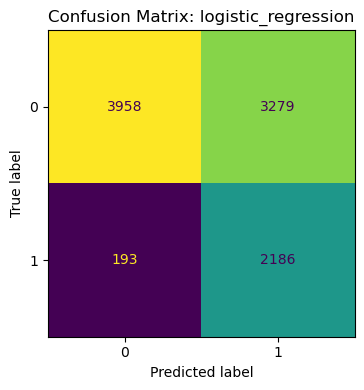

Training mlp_existing_impl...


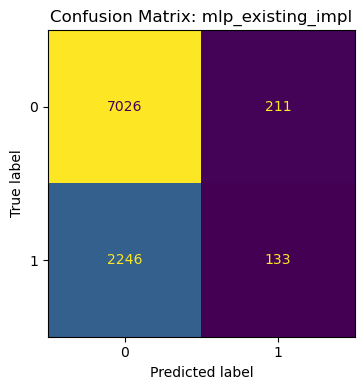

,model,accuracy,f1,precision,recall,roc_auc
1,mlp_existing_impl,0.744488,0.097686,0.386628,0.055906,0.755510
0,logistic_regression,0.638935,0.557369,0.400000,0.918873,0.747968


In [25]:
preprocessor = make_preprocessor(numeric_features, categorical_features)
models = build_models(preprocessor, HIDDEN_LAYERS)

validation_results = []
fitted_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    metrics = evaluate_model(
        model_name, model, X_train, y_train, X_val, y_val, out_dir
    )
    validation_results.append(metrics)
    fitted_models[model_name] = joblib.load(out_dir / f"{model_name}.joblib")

validation_metrics_df = pd.DataFrame([
    {
        "model": x["model"],
        "accuracy": x["accuracy"],
        "f1": x["f1"],
        "precision": x["precision"],
        "recall": x["recall"],
        "roc_auc": x["roc_auc"],
    }
    for x in validation_results
]).sort_values("roc_auc", ascending=False)

validation_metrics_df

## 7. Evaluate the best validation model on the test set

Best model by validation ROC-AUC: mlp_existing_impl


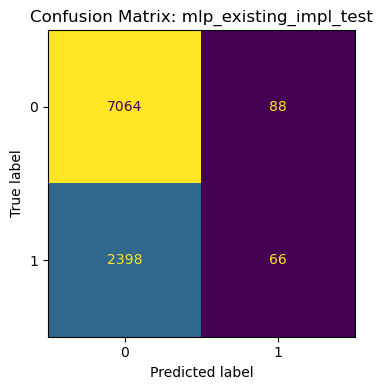

,model,accuracy,f1,precision,recall,roc_auc
0,mlp_existing_impl_test,0.741473,0.05042,0.428571,0.026786,0.754012


In [26]:
best_model_name = max(validation_results, key=lambda x: x["roc_auc"])["model"]
print("Best model by validation ROC-AUC:", best_model_name)

best_model = build_models(
    make_preprocessor(numeric_features, categorical_features),
    HIDDEN_LAYERS
)[best_model_name]

X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

test_metrics = evaluate_model(
    f"{best_model_name}_test",
    best_model,
    X_trainval,
    y_trainval,
    X_test,
    y_test,
    out_dir,
)

test_metrics_df = pd.DataFrame([{
    "model": test_metrics["model"],
    "accuracy": test_metrics["accuracy"],
    "f1": test_metrics["f1"],
    "precision": test_metrics["precision"],
    "recall": test_metrics["recall"],
    "roc_auc": test_metrics["roc_auc"],
}])

display(test_metrics_df)

## 8. Save experiment summaries

In [27]:
summary = {
    "csv_path": str(Path(CSV_PATH).resolve()),
    "rows": int(len(df)),
    "columns": list(df.columns),
    "target_percentile": TARGET_PERCENTILE,
    "engagement_threshold_from_train": threshold,
    "feature_mode": FEATURE_MODE,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "best_model_by_validation_roc_auc": best_model_name,
    "validation_results": validation_results,
    "test_result_of_best_model": test_metrics,
    "split_sizes": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "class_balance": {
        "train_positive_rate": float(y_train.mean()),
        "validation_positive_rate": float(y_val.mean()),
        "test_positive_rate": float(y_test.mean()),
    },
}

with open(out_dir / "metrics_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

validation_metrics_df.to_csv(out_dir / "validation_metrics.csv", index=False)
test_metrics_df.to_csv(out_dir / "test_metrics.csv", index=False)

print("Saved files to:", out_dir.resolve())
print(sorted([p.name for p in out_dir.iterdir()]))

Saved files to: C:\Users\Allysa\Downloads\CSC753M\outputs_notebook
['logistic_regression.joblib', 'logistic_regression_confusion_matrix.png', 'metrics_summary.json', 'mlp_existing_impl.joblib', 'mlp_existing_impl_confusion_matrix.png', 'mlp_existing_impl_test.joblib', 'mlp_existing_impl_test_confusion_matrix.png', 'test_metrics.csv', 'validation_metrics.csv']


## 9. Notes for the paper

Use these in your methodology and results sections:

1. **Target definition**  
   The label is built from engagement rate:
   \[
   engagement\_rate = \frac{likes + comments + shares}{views}
   \]
   Videos at or above the chosen percentile threshold are labeled **high engagement = 1**.

2. **Strict mode is recommended**  
   `FEATURE_MODE = "strict"` excludes raw engagement columns used to derive the target, which helps reduce **target leakage**.

3. **Model comparison**  
   Report the Logistic Regression result as the **linear baseline** and the MLP result as the **deep learning model**.

4. **Suggested metrics to report**  
   Accuracy, Precision, Recall, F1-score, and ROC-AUC.
